# ST40 Li powder dropper: lithium results (SOLPS-13589_2 background)

Output of `in.openedge` (constant powder feed, background
`input/plasma_13589.h5`, `chem_mode neutral`: Li is removed at ionization and
handed to SOLPS as a source), read from `runs/s200000_n16_4010` and `runs/s200000_n16_4010.log`.
The dumps use the axisymmetric layout, (x, y) = (Z, R), and are swapped to
(R, Z) here. Time is simulation time from the first grain release; the powder takes about 200 ms to reach the plasma.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

CASE = Path.cwd().resolve()
if CASE.name == "notebooks":
    CASE = CASE.parent
sys.path.insert(0, str(CASE / "scripts"))
from plot_lpd import snapshots, surf_loop, read_surf_pts   # sets the Agg backend; restore inline below
%matplotlib inline

OE_OUT = CASE / "runs/s200000_n16_4010"
LOG = CASE / "runs/s200000_n16_4010.log"
print("reading", OE_OUT, "and", LOG.name)
assert (OE_OUT / "state").exists(), "no OpenEdge output found; run in.openedge first"

DT = 2.0e-6
NX, NY = 260, 144                      # create_grid in in.openedge (base cells for the maps)
SPECIES = {1: "grain", 2: "Li", 3: "Li$^+$"}
COLORS = {1: "silver", 2: "red", 3: "limegreen"}
plt.rcParams.update({"font.size": 12, "axes.titlesize": 13, "figure.dpi": 110})

wall_x, wall_y = surf_loop(CASE / "input/st40_wall_axi.surf")
core_x, core_y = surf_loop(CASE / "input/st40_core.surf")
wall_pts = read_surf_pts(CASE / "input/st40_wall_axi.surf")
drop = [wall_pts[i] for i in (15, 16, 17)]

def vessel(ax):
    ax.plot(wall_x, wall_y, "-", color="0.2", lw=1.3, zorder=5)
    ax.plot(core_x, core_y, "--", color="royalblue", lw=0.9, zorder=4)
    ax.plot([p[0] for p in drop], [p[1] for p in drop], "-", color="black", lw=3.5, zorder=6)
    ax.set_aspect("equal"); ax.set_xlabel("R (m)"); ax.set_ylabel("Z (m)")

reading /Users/42d/OpenEdge/examples/workflows/particulates/st40_lithium_powder_dropper/openedge/runs/s200000_n16_4010 and s200000_n16_4010.log


## Particle snapshot

Grains and the four Li species at the last dumped step.

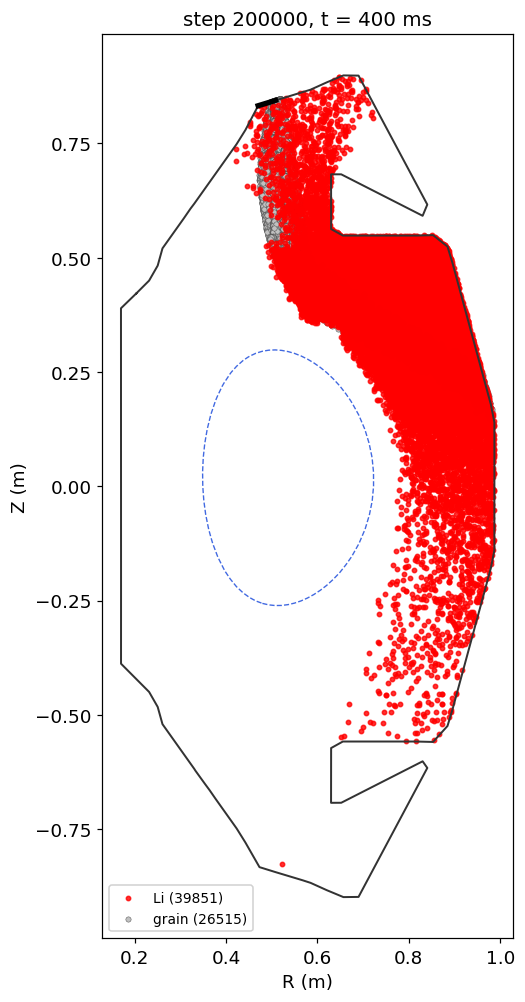

{'grain': 26515, 'Li': 39851, 'Li$^+$': 0}


In [2]:
frames = snapshots(OE_OUT / "state")
step, hdr, rows = frames[-1]
ti, xi, yi = hdr.index("type"), hdr.index("x"), hdr.index("y")
P = {t: np.array([[float(r[yi]), float(r[xi])] for r in rows if int(r[ti]) == t]).reshape(-1, 2) for t in SPECIES}
fig, ax = plt.subplots(figsize=(6, 9), constrained_layout=True)
vessel(ax)
style = {3: dict(s=2, alpha=0.35), 2: dict(s=8, alpha=0.8), 1: dict(s=12, edgecolor="0.3", lw=0.3)}
for t in (3, 2, 1):
    if len(P[t]):
        ax.scatter(P[t][:, 0], P[t][:, 1], color=COLORS[t], zorder=2 + 0.1 * t,
                   label=f"{SPECIES[t]} ({len(P[t])})", **style[t])
ax.set_title(f"step {step}, t = {step*DT*1e3:.0f} ms")
ax.legend(loc="lower left", fontsize=9, framealpha=0.9); plt.show()
print({SPECIES[t]: len(P[t]) for t in SPECIES})

## Powder and lithium density

Time-averaged `nrho_w` from the grid dump (`fix ave/grid`, 20 ms windows): grains
and neutral Li, each on its own log scale. With a constant feed the run is
steady after about +20 ms (step 120k), so all windows from `STEADY_FROM` on are averaged.

frames (step, Li total): [(150000, '3.43e+19'), (160000, '3.47e+19'), (170000, '3.46e+19'), (180000, '3.48e+19'), (190000, '3.49e+19'), (200000, '3.46e+19')]


averaging 9 windows, steps 120000..200000 (180 ms of samples)


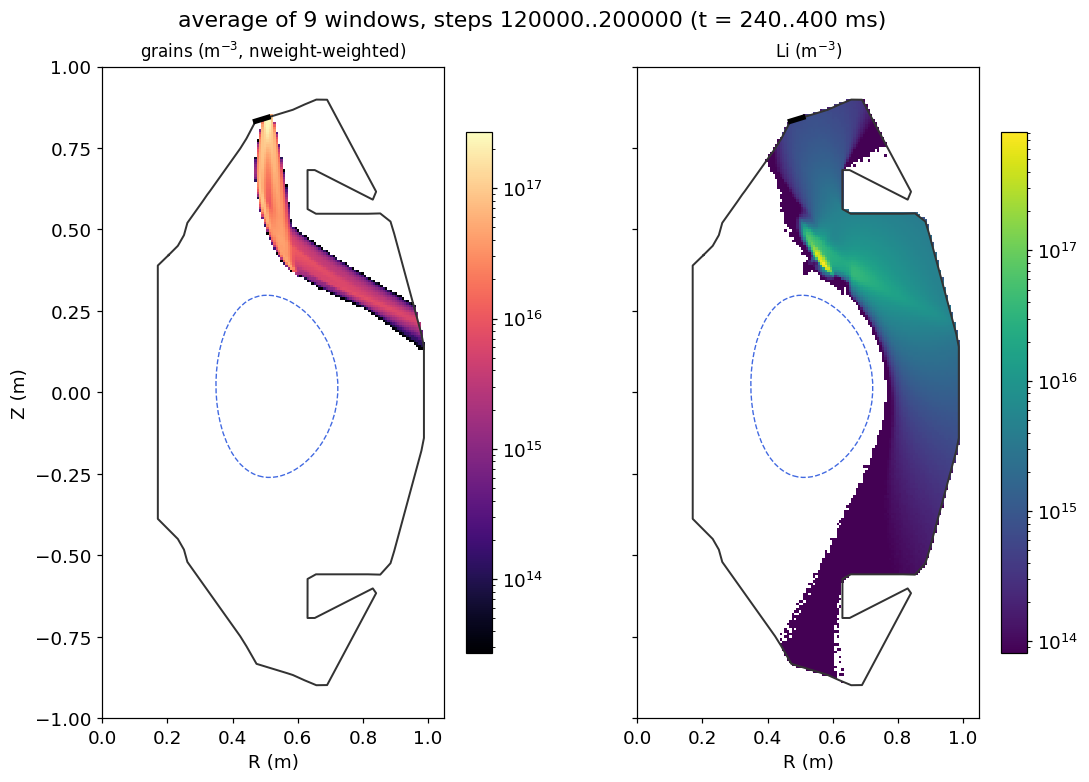

In [3]:
snaps = snapshots(OE_OUT / "li_dens")
li_col = 1                           # dump columns after id,xc,yc: grains, Li (older dumps add Li+)
totals = [(s, sum(float(r[3 + li_col]) for r in rows)) for s, hdr, rows in snaps]
print("frames (step, Li total):", [(s, f"{t:.2e}") for s, t in totals[-6:]])
# Steady feed: average every window from STEADY_FROM on (set STEADY_FROM = None for the peak window only)
STEADY_FROM = 120000
use = [f for f in snaps if STEADY_FROM is not None and f[0] >= STEADY_FROM and f[0] > 0] or [max(snaps, key=lambda f: dict(totals)[f[0]])]
# dumps list cells in per-rank order that changes with every rebalance: align frames by cell id
def by_id(rows):
    a = np.array([[float(v) for v in r] for r in rows]); return a[np.argsort(a[:, 0])]
gstep = use[-1][0]
frames_sorted = [by_id(f[2]) for f in use]
assert all(np.array_equal(fr[:, 0], frames_sorted[0][:, 0]) for fr in frames_sorted), "cell id sets differ between frames"
Zc, Rc = frames_sorted[0][:, 1], frames_sorted[0][:, 2]
data = np.mean([fr[:, 3:] for fr in frames_sorted], axis=0)
print(f"averaging {len(use)} windows, steps {use[0][0]}..{gstep} ({len(use)*20} ms of samples)")
nx, ny = NX, NY
Rg = np.linspace(0, 1.05, ny + 1); Zg = np.linspace(-1, 1, nx + 1)
def grid(Z, R, v):
    ix = np.clip(((Z + 1.0) / (2.0 / nx)).astype(int), 0, nx - 1); iy = np.clip((R / (1.05 / ny)).astype(int), 0, ny - 1)
    img = np.zeros((ny, nx)); cnt = np.zeros((ny, nx)); np.add.at(img, (iy, ix), v); np.add.at(cnt, (iy, ix), 1)
    return np.where(cnt > 0, img / np.maximum(cnt, 1), np.nan)
panels = [("grains (m$^{-3}$, nweight-weighted)", grid(Zc, Rc, data[:, 0]), "magma"),
          ("Li (m$^{-3}$)", grid(Zc, Rc, data[:, li_col]), "viridis")]
fig, axs = plt.subplots(1, 2, figsize=(10, 7), sharey=True, constrained_layout=True)
for ax, (lab, img, cmap) in zip(axs, panels):
    pos = img[np.isfinite(img) & (img > 0)]
    if pos.size:
        pm = ax.pcolormesh(0.5 * (Rg[:-1] + Rg[1:]), 0.5 * (Zg[:-1] + Zg[1:]), np.where(img > 0, img, np.nan).T,
                           norm=LogNorm(max(pos.max() * 1e-4, pos.min()), pos.max()), cmap=cmap, shading="auto")
        fig.colorbar(pm, ax=ax, shrink=0.8)
    else:
        ax.text(0.5, 0.5, "empty", transform=ax.transAxes, ha="center")
    vessel(ax); ax.set_title(lab, fontsize=11)
    if ax is not axs[0]: ax.set_ylabel("")
fig.suptitle(f"average of {len(use)} windows, steps {use[0][0]}..{gstep} (t = {use[0][0]*DT*1e3:.0f}..{gstep*DT*1e3:.0f} ms)")
plt.show()

## Inventories versus time

Macroparticle counts per species from the `stats` block of the log.

41 stats samples, columns ['Step', 'CPU', 'Np', 'Nscoll', 'Nsreact', 'c_cnt[1]', 'c_cnt[2]', 'c_cSp_tot', 'c_cSe_tot']


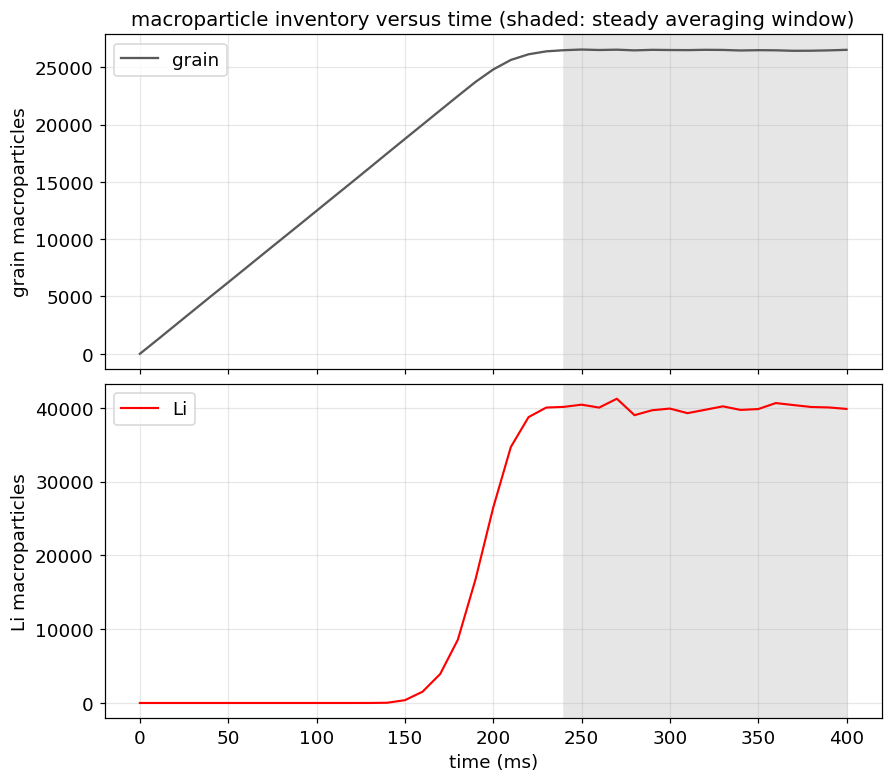

In [4]:
rows, names = [], None
for l in LOG.read_text().splitlines():
    p = l.split()
    if p[:2] == ["Step", "CPU"]: names = p; continue
    if names and len(p) == len(names):
        try: rows.append([float(v) for v in p])
        except ValueError: pass
a = np.array(rows); print(f"{len(a)} stats samples, columns {names}")
t = a[:, 0] * DT * 1e3
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, constrained_layout=True)
ax1.plot(t, a[:, names.index("c_cnt[1]")], color="0.35", lw=1.5, label="grain"); ax1.set_ylabel("grain macroparticles"); ax1.legend()
ax2.plot(t, a[:, names.index("c_cnt[2]")], color="red", lw=1.4, label="Li")
if "c_cnt[3]" in names: ax2.plot(t, a[:, names.index("c_cnt[3]")], color="limegreen", lw=1.4, label="Li$^+$ (kinetic-mode run)")
ax2.set_ylabel("Li macroparticles"); ax2.set_xlabel("time (ms)"); ax2.legend()
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.axvspan(STEADY_FROM * DT * 1e3, t[-1], color="0.9", zorder=0)
ax1.set_title("macroparticle inventory versus time (shaded: steady averaging window)")
plt.show()

## SOLPS coupling sources

Per-cell particle source Sp (positive = net ionization) and electron-energy
source Qe (negative = ionization cost plus line radiation) from
`fix volume/chem/adas`, averaged over 20 ms windows and dumped as
`source_SpSe.<step>`. These are the fields `tools/coupling/source_spse_to_solps.py`
maps onto the B2 grid (`sna0` and `she0`). The deck runs `chem_mode neutral`, so
Sp is the Li+ birth source that SOLPS then transports.

    step   t (ms)   int Sp dV (Li/s)    int Qe dV (W)
       0        0          0.000e+00        0.000e+00
   10000       20          0.000e+00        0.000e+00
   20000       40          0.000e+00        0.000e+00
   30000       60          0.000e+00        0.000e+00
   40000       80          0.000e+00        0.000e+00
   50000      100          0.000e+00        0.000e+00
   60000      120          0.000e+00        0.000e+00
   70000      140          2.960e+16       -1.438e-01
   80000      160          8.457e+18       -3.511e+01
   90000      180          1.082e+20       -3.989e+02
  100000      200          7.050e+20       -2.151e+03
  110000      220          1.608e+21       -4.564e+03
  120000      240          1.827e+21       -5.112e+03
  130000      260          1.773e+21       -4.972e+03
  140000      280          1.818e+21       -5.084e+03
  150000      300          1.767e+21       -4.960e+03
  160000      320          1.835e+21       -5.128e+03
  170000      340          1

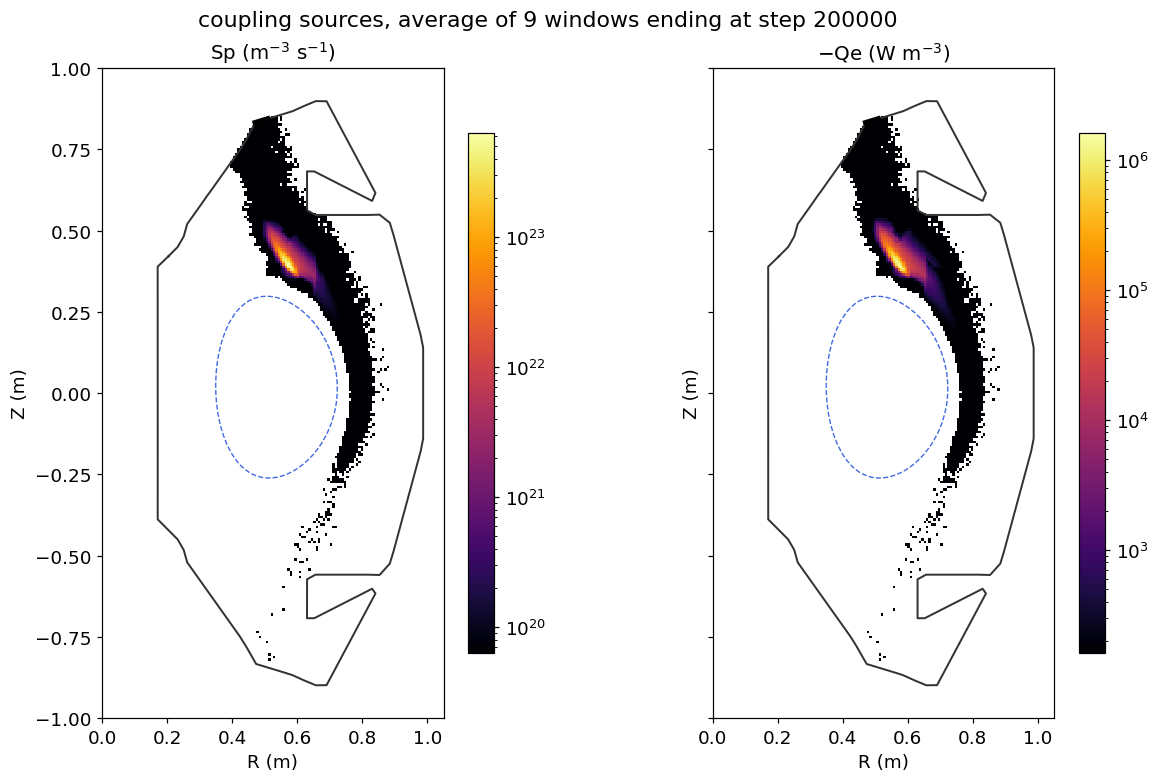

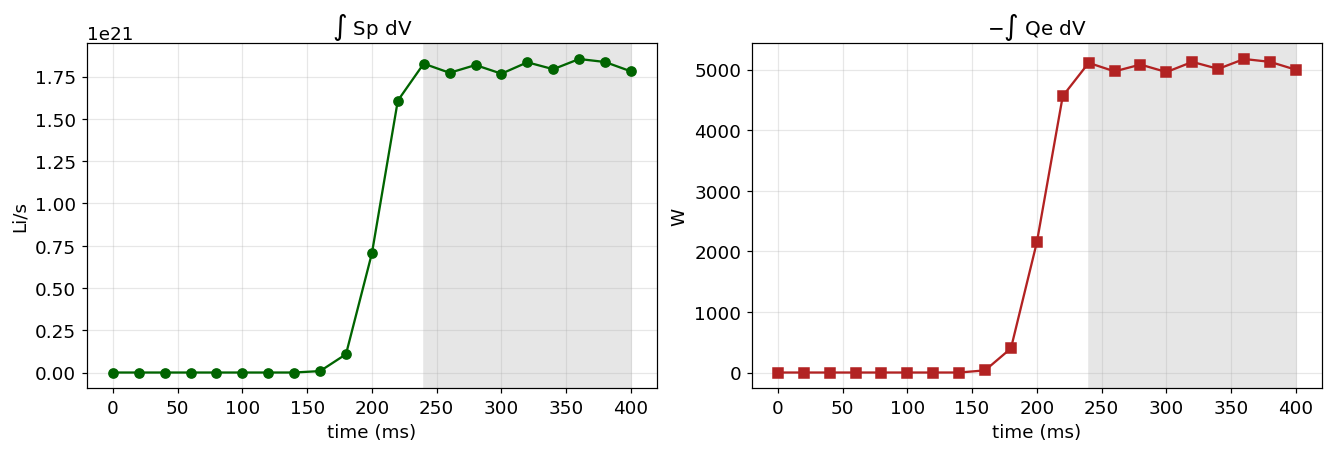

electron energy per ionization: 17.5 eV (median over windows)


In [5]:
import glob
sfiles = sorted(glob.glob(str(OE_OUT / "source_SpSe.*")), key=lambda f: int(f.rsplit(".", 1)[1]))
hist = []
for f in sfiles:
    sstep, shdr, srows = snapshots(f)[0]
    arr = np.array([[float(v) for v in r] for r in srows])
    col = {k: i for i, k in enumerate(shdr)}
    vol = arr[:, col["vol"]]; Sp = arr[:, col["f_fsrc[1]"]]; Qe = arr[:, col["f_fsrc[5]"]]
    hist.append((sstep, float((Sp * vol).sum()), float((Qe * vol).sum()), arr, col))
print(f"{'step':>8} {'t (ms)':>8} {'int Sp dV (Li/s)':>18} {'int Qe dV (W)':>16}")
for sstep, isp, iqe, *_ in hist:
    print(f"{sstep:8d} {sstep*DT*1e3:8.0f} {isp:18.3e} {iqe:16.3e}")
steady = [h for h in hist if h[0] >= STEADY_FROM] or [max(hist, key=lambda h: abs(h[1]))]
if abs(steady[-1][1]) > 0:
    sstep, col = steady[-1][0], steady[-1][4]
    arr = np.mean([h[3][np.argsort(h[3][:, 0])] for h in steady], axis=0)   # align by cell id
    print(f"source maps: average of {len(steady)} windows from step {steady[0][0]}")
    Zs, Rs = arr[:, col["xc"]], arr[:, col["yc"]]
    ixs = np.clip(((Zs + 1.0) / (2.0 / nx)).astype(int), 0, nx - 1); iys = np.clip((Rs / (1.05 / ny)).astype(int), 0, ny - 1)
    def grid_s(v):
        img = np.zeros((ny, nx)); cnt = np.zeros((ny, nx)); np.add.at(img, (iys, ixs), v); np.add.at(cnt, (iys, ixs), 1)
        return np.where(cnt > 0, img / np.maximum(cnt, 1), np.nan)
    Sp_img = grid_s(arr[:, col["f_fsrc[1]"]]); Qe_img = grid_s(-arr[:, col["f_fsrc[5]"]])
    fig, axs = plt.subplots(1, 2, figsize=(11, 7), sharey=True, constrained_layout=True)
    for ax, img, lab in ((axs[0], Sp_img, "Sp (m$^{-3}$ s$^{-1}$)"), (axs[1], Qe_img, "$-$Qe (W m$^{-3}$)")):
        pos = img[np.isfinite(img) & (img > 0)]
        pm = ax.pcolormesh(0.5 * (Rg[:-1] + Rg[1:]), 0.5 * (Zg[:-1] + Zg[1:]), np.where(img > 0, img, np.nan).T,
                           norm=LogNorm(max(pos.max() * 1e-4, 1e-30), pos.max()), cmap="inferno", shading="auto")
        vessel(ax); ax.set_title(lab); fig.colorbar(pm, ax=ax, shrink=0.8)
    fig.suptitle(f"coupling sources, average of {len(steady)} windows ending at step {sstep}")
    plt.show()
    t_h = np.array([h[0] for h in hist]) * DT * 1e3
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    ax1.plot(t_h, [h[1] for h in hist], "o-", color="darkgreen"); ax1.set(xlabel="time (ms)", ylabel="Li/s", title="$\int$ Sp dV")
    ax2.plot(t_h, [-h[2] for h in hist], "s-", color="firebrick"); ax2.set(xlabel="time (ms)", ylabel="W", title="$-\int$ Qe dV")
    for ax in (ax1, ax2): ax.grid(alpha=0.3); ax.axvspan(STEADY_FROM * DT * 1e3, t_h[-1], color="0.9", zorder=0)
    plt.show()
    ratio = np.array([-h[2] / h[1] for h in hist if h[1] > 0]) / 1.602e-19
    print(f"electron energy per ionization: {np.median(ratio):.1f} eV (median over windows)")
else:
    print("no ionization yet in any window; the source maps need a longer run")

## On the SOLPS grid: what the coupling hands over

The steady-window averages above, conservatively mapped onto the SOLPS B2 cells
the way `tools/coupling/source_spse_to_solps.py` does it (each OpenEdge cell's
integrated source goes to the nearest B2 cell centre, then divided by the B2 cell
volume). This is the view used in the LM paper figures, and it is literally the
`sna0` and `she0` input SOLPS will read; Li+ itself lives in SOLPS. Full-range
log scales; cells without source sit at the floor.

mapped 15852/39999 OpenEdge cells; conserved: Sp 1.809e+21 Li/s (OE 1.809e+21), Qe 5.064e+03 W


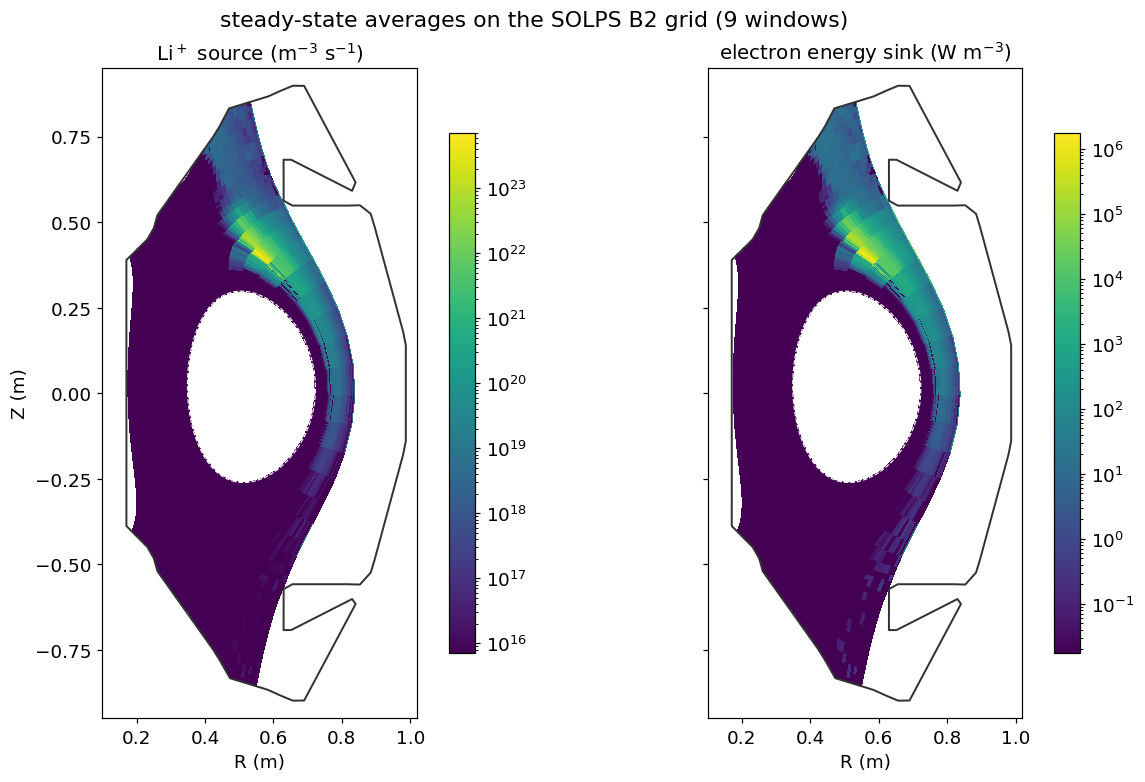

In [6]:
import h5py
from matplotlib.collections import PolyCollection
from scipy.spatial import cKDTree
with h5py.File(CASE / "input/plasma_13589.h5", "r") as hb:
    polys = hb["b2/cell_polygons"][...]; b2r = hb["b2/r_center"][...]; b2z = hb["b2/z_center"][...]
area_b2 = 0.5 * np.abs(np.sum(polys[:, :, 0] * np.roll(polys[:, :, 1], -1, axis=1) - np.roll(polys[:, :, 0], -1, axis=1) * polys[:, :, 1], axis=1))
vol_b2 = 2 * np.pi * polys[:, :, 0].mean(1) * area_b2
real = area_b2 > 1e-10
tree = cKDTree(np.column_stack([b2r[real], b2z[real]]))

# OpenEdge cells of the averaged source dump: id, xc(Z), yc(R), vol, Sp, Qe
oe_R, oe_Z, oe_vol = arr[:, col["yc"]], arr[:, col["xc"]], arr[:, col["vol"]]
dist, j = tree.query(np.column_stack([oe_R, oe_Z]))
inside = dist < 0.05                      # same max_dist as the coupling script
def to_b2(per_cell_density):
    tot = np.zeros(real.sum()); np.add.at(tot, j[inside], (per_cell_density * oe_vol)[inside])
    return tot, tot / vol_b2[real]
Sp_tot, Sp_b2 = to_b2(arr[:, col["f_fsrc[1]"]]); Qe_tot, Qe_b2 = to_b2(-arr[:, col["f_fsrc[5]"]])
print(f"mapped {inside.sum()}/{len(oe_R)} OpenEdge cells; conserved: Sp {Sp_tot.sum():.3e} Li/s (OE {np.sum(arr[:, col['f_fsrc[1]']]*oe_vol):.3e}), Qe {Qe_tot.sum():.3e} W")

fig, axs = plt.subplots(1, 2, figsize=(11, 7), sharey=True, constrained_layout=True)
for ax, vals, lab, cmap, decades in ((axs[0], Sp_b2, "Li$^+$ source (m$^{-3}$ s$^{-1}$)", "viridis", 8),
                                     (axs[1], Qe_b2, "electron energy sink (W m$^{-3}$)", "viridis", 8)):
    vmax = vals.max(); vmin = vmax * 10.0 ** (-decades)
    pc = PolyCollection(polys[real], array=np.maximum(vals, vmin), cmap=cmap, norm=LogNorm(vmin, vmax),
                        edgecolors="none", antialiased=False)
    ax.add_collection(pc); fig.colorbar(pc, ax=ax, shrink=0.8)
    ax.plot(wall_x, wall_y, "-", color="0.2", lw=1.3); ax.plot(core_x, core_y, "--", color="w", lw=0.8)
    ax.set_xlim(0.1, 1.02); ax.set_ylim(-0.95, 0.95); ax.set_aspect("equal")
    ax.set_xlabel("R (m)"); ax.set_title(lab)
axs[0].set_ylabel("Z (m)")
fig.suptitle(f"steady-state averages on the SOLPS B2 grid ({len(steady)} windows)")
plt.show()